# Herramienta Interactiva de Visualización y Análisis Espaciotemporal de la Sismicidad en Chile
### Cuaderno de Trabajo y Experimentación: Caso de Estudio Terremoto de Illapel 2015 ($M_w\ 8.3$)

**Asignatura:** EIN092B Visualización de Datos  
**Profesor:** Jorge Portilla  
**Autores:** Fabian Acuña, Fernando Gutiérrez  

---

## Propósito y Estructura General del Proyecto
Este cuaderno sirve como base experimental y metodológica para la **Segunda Entrega (Informe Final en Formato Paper IEEE)**.

El objetivo es estudiar la secuencia sísmica asociada al terremoto de Illapel del 16 de septiembre de 2015 ($M_w\ 8.3$), integrando técnicas de análisis espaciotemporal y agrupamiento no supervisado (DBSCAN) para superar las limitaciones de los catálogos tradicionales en 2D y tablas estáticas.

A continuación se detallan las **7 etapas lógicas** que desarrollaremos juntos paso a paso.

## Etapa 1: Obtención automática y reproducible de los datos

### ¿Qué haremos en esta etapa?

- Definir los parámetros necesarios para realizar consultas a la API pública del **Servicio Geológico de Estados Unidos (USGS)**.
- Establecer el periodo de tiempo que se va a analizar, desde el **15 de septiembre de 2015 hasta el 15 de octubre de 2015**, considerando un mes en el que ocurrió el evento principal y sus réplicas más importantes.
- Delimitar la zona geográfica del análisis, correspondiente al centro-norte de Chile (Latitud [-35.0, -28.0], Longitud [-74.0, -69.0]).
- Definir una magnitud mínima de **$M \ge 3.0$**, para centrar el análisis en sismos de mayor relevancia y evitar incluir demasiados eventos de baja magnitud.
- Implementar un código que descargue automáticamente el archivo CSV si este no se encuentra disponible en el entorno. De esta forma, cualquier persona que abra el cuaderno de Google Colab, incluido el profesor, podrá ejecutarlo sin necesidad de realizar descargas manuales.

### Variables que obtendremos de la API:

- `time`: Fecha y hora en UTC en que ocurrió el sismo.
- `latitude`, `longitude`: Coordenadas donde se encuentra el epicentro del sismo.
- `depth`: Profundidad del hipocentro en kilómetros. Esta variable permite conocer qué tan profundo ocurrió el sismo, algo que no se puede apreciar correctamente en una representación tradicional en 2D.
- `mag`: Magnitud registrada del sismo.
- `place`: Descripción de la ubicación geográfica donde ocurrió el evento sísmico.

In [ ]:
import os
import pandas as pd
# 1. Definición de parámetros para la API pública del USGS
# Terremoto de Illapel: 16 de septiembre de 2015
# Ventana: 15-09-2015 al 15-10-2015 (1 mes completo de evento principal + réplicas)
# Región Coquimbo/Centro-Norte de Chile: Latitud [-35.0, -28.0], Longitud [-74.0, -69.0]
# Umbral: Magnitud >= 3.0
USGS_API_URL = (
    "https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv"
    "&starttime=2015-09-15"
    "&endtime=2015-10-15"
    "&minmagnitude=3.0"
    "&minlatitude=-35.0"
    "&maxlatitude=-28.0"
    "&minlongitude=-74.0"
    "&maxlongitude=-69.0"
)
CSV_FILENAME = "illapel_2015_usgs.csv"
# 2. Descarga inteligente y autónoma
if not os.path.exists(CSV_FILENAME):
    print("Descargando catálogo directamente desde la API oficial de USGS...")
    df_raw = pd.read_csv(USGS_API_URL)
    df_raw.to_csv(CSV_FILENAME, index=False)
    print(f"¡Descarga exitosa! Archivo guardado localmente como '{CSV_FILENAME}'")
else:
    print(f"Cargando archivo local existente '{CSV_FILENAME}'...")
    df_raw = pd.read_csv(CSV_FILENAME)
print(f"Total de registros descargados: {len(df_raw)}")
df_raw.head(3)

Descargando catálogo directamente desde la API oficial de USGS...
¡Descarga exitosa! Archivo guardado localmente como 'illapel_2015_usgs.csv'
Total de registros descargados: 719


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2015-10-14T11:30:42.310Z,-33.3580,-72.6858,10.00,4.4,mwr,NaN,173.0,0.940,0.76,...,2016-01-11T21:07:26.040Z,"102 km WNW of Cartagena, Chile",earthquake,2.8,1.9,0.056,31.0,reviewed,us,us
1,2015-10-14T08:35:37.000Z,-31.2640,-71.4600,49.90,4.2,mb,NaN,NaN,NaN,1.35,...,2016-01-11T21:07:26.040Z,"49 km NW of Illapel, Chile",earthquake,7.6,6.8,0.305,3.0,reviewed,guc,us
2,2015-10-14T03:48:00.660Z,-30.3953,-71.8561,18.41,4.2,mb,NaN,149.0,0.336,0.64,...,2016-01-11T21:07:25.040Z,"67 km WNW of Ovalle, Chile",earthquake,3.9,5.2,0.264,4.0,reviewed,us,us


---

## Etapa 2: Exploración, limpieza y organización de los datos

### ¿Qué haremos en esta etapa?

- **Control de integridad:** Revisar si existen valores nulos, registros duplicados o datos inconsistentes en los campos numéricos, para corregirlos o tratarlos según corresponda.
- **Normalización temporal:** Convertir los datos de texto del campo `time` a formato `datetime` utilizando Pandas y manteniendo la zona horaria UTC. Además, ordenar los registros según la fecha y hora en que ocurrieron los sismos.
- **Detección automática del sismo principal (*Mainshock*):** Identificar mediante código el sismo de mayor magnitud ($M_w\ 8.3$), para utilizarlo como referencia tanto en la ubicación como en el tiempo durante el análisis.
- **Resumen estadístico inicial:** Obtener información general de los datos, como la cantidad total de sismos, el rango de profundidades y la distribución de magnitudes, antes de comenzar a aplicar los modelos.

In [ ]:
# 1. Copia de seguridad y normalización de marcas temporales
df = df_raw.copy()
df['datetime'] = pd.to_datetime(df['time'])

# 2. Selección de columnas sismológicas esenciales
cols_interes = ['datetime', 'latitude', 'longitude', 'depth', 'mag', 'place']
df = df[cols_interes]

# 3. Limpieza de calidad: eliminar nulos, duplicados y ordenar cronológicamente
df = df.dropna().drop_duplicates().sort_values('datetime').reset_index(drop=True)

# 4. Detección automática del Sismo Principal (Mainshock)
idx_principal = df['mag'].idxmax()
mainshock = df.loc[idx_principal]

print("=== SISMO PRINCIPAL DETECTADO (ILLAPEL 2015) ===")
print(f"Fecha y Hora (UTC): {mainshock['datetime']}")
print(f"Magnitud: Mw {mainshock['mag']}")
print(f"Epicentro: Latitud {mainshock['latitude']}°, Longitud {mainshock['longitude']}°")
print(f"Profundidad Hipocentral: {mainshock['depth']} km")
print(f"Referencia geográfica: {mainshock['place']}")
print("-" * 50)
print(f"Total de eventos limpios y válidos para modelar: {len(df)}")

=== SISMO PRINCIPAL DETECTADO (ILLAPEL 2015) ===
Fecha y Hora (UTC): 2015-09-16 22:54:32.860000+00:00
Magnitud: Mw 8.3
Epicentro: Latitud -31.5729°, Longitud -71.6744°
Profundidad Hipocentral: 22.44 km
Referencia geográfica: 48 km W of Illapel, Chile
--------------------------------------------------
Total de eventos limpios y válidos para modelar: 719


---

## Etapa 3: Selección de parámetros del modelo DBSCAN mediante el gráfico k-Distance

### ¿Qué haremos en esta etapa?

> **Importante para la evaluación:** En la primera entrega, el profesor indicó que la selección de los modelos y sus parámetros debe estar respaldada por criterios objetivos y no por valores elegidos al azar.

- El algoritmo de agrupamiento **DBSCAN** necesita dos parámetros principales:
  1. $\varepsilon$ (*epsilon*): Define el radio de distancia que se utilizará para considerar dos eventos como vecinos.
  2. $MinPts$ (*min_samples*): Indica la cantidad mínima de sismos que deben encontrarse dentro del radio $\varepsilon$ para formar una zona densa.
- Como trabajaremos con tres dimensiones ($X, Y, Z$ = Latitud, Longitud y Profundidad), primero normalizaremos las variables para que las diferencias entre grados y kilómetros no afecten los resultados del modelo.
- Tomando como referencia el criterio técnico de $MinPts \ge 2 \times \text{dimensiones}$, estableceremos $MinPts = k$.
- Calcularemos la distancia de cada sismo hasta su vecino número $k$ más cercano y representaremos los resultados mediante un gráfico de distancias ordenadas (**k-distance graph**).
- A partir del gráfico, buscaremos el punto donde se produce el cambio más pronunciado en la curva (**método del codo**), lo que nos permitirá establecer el valor de $\varepsilon$ con un criterio fundamentado y no de manera arbitraria.
- Finalmente, exportaremos este gráfico para utilizarlo como la **Figura 2** de nuestro paper.

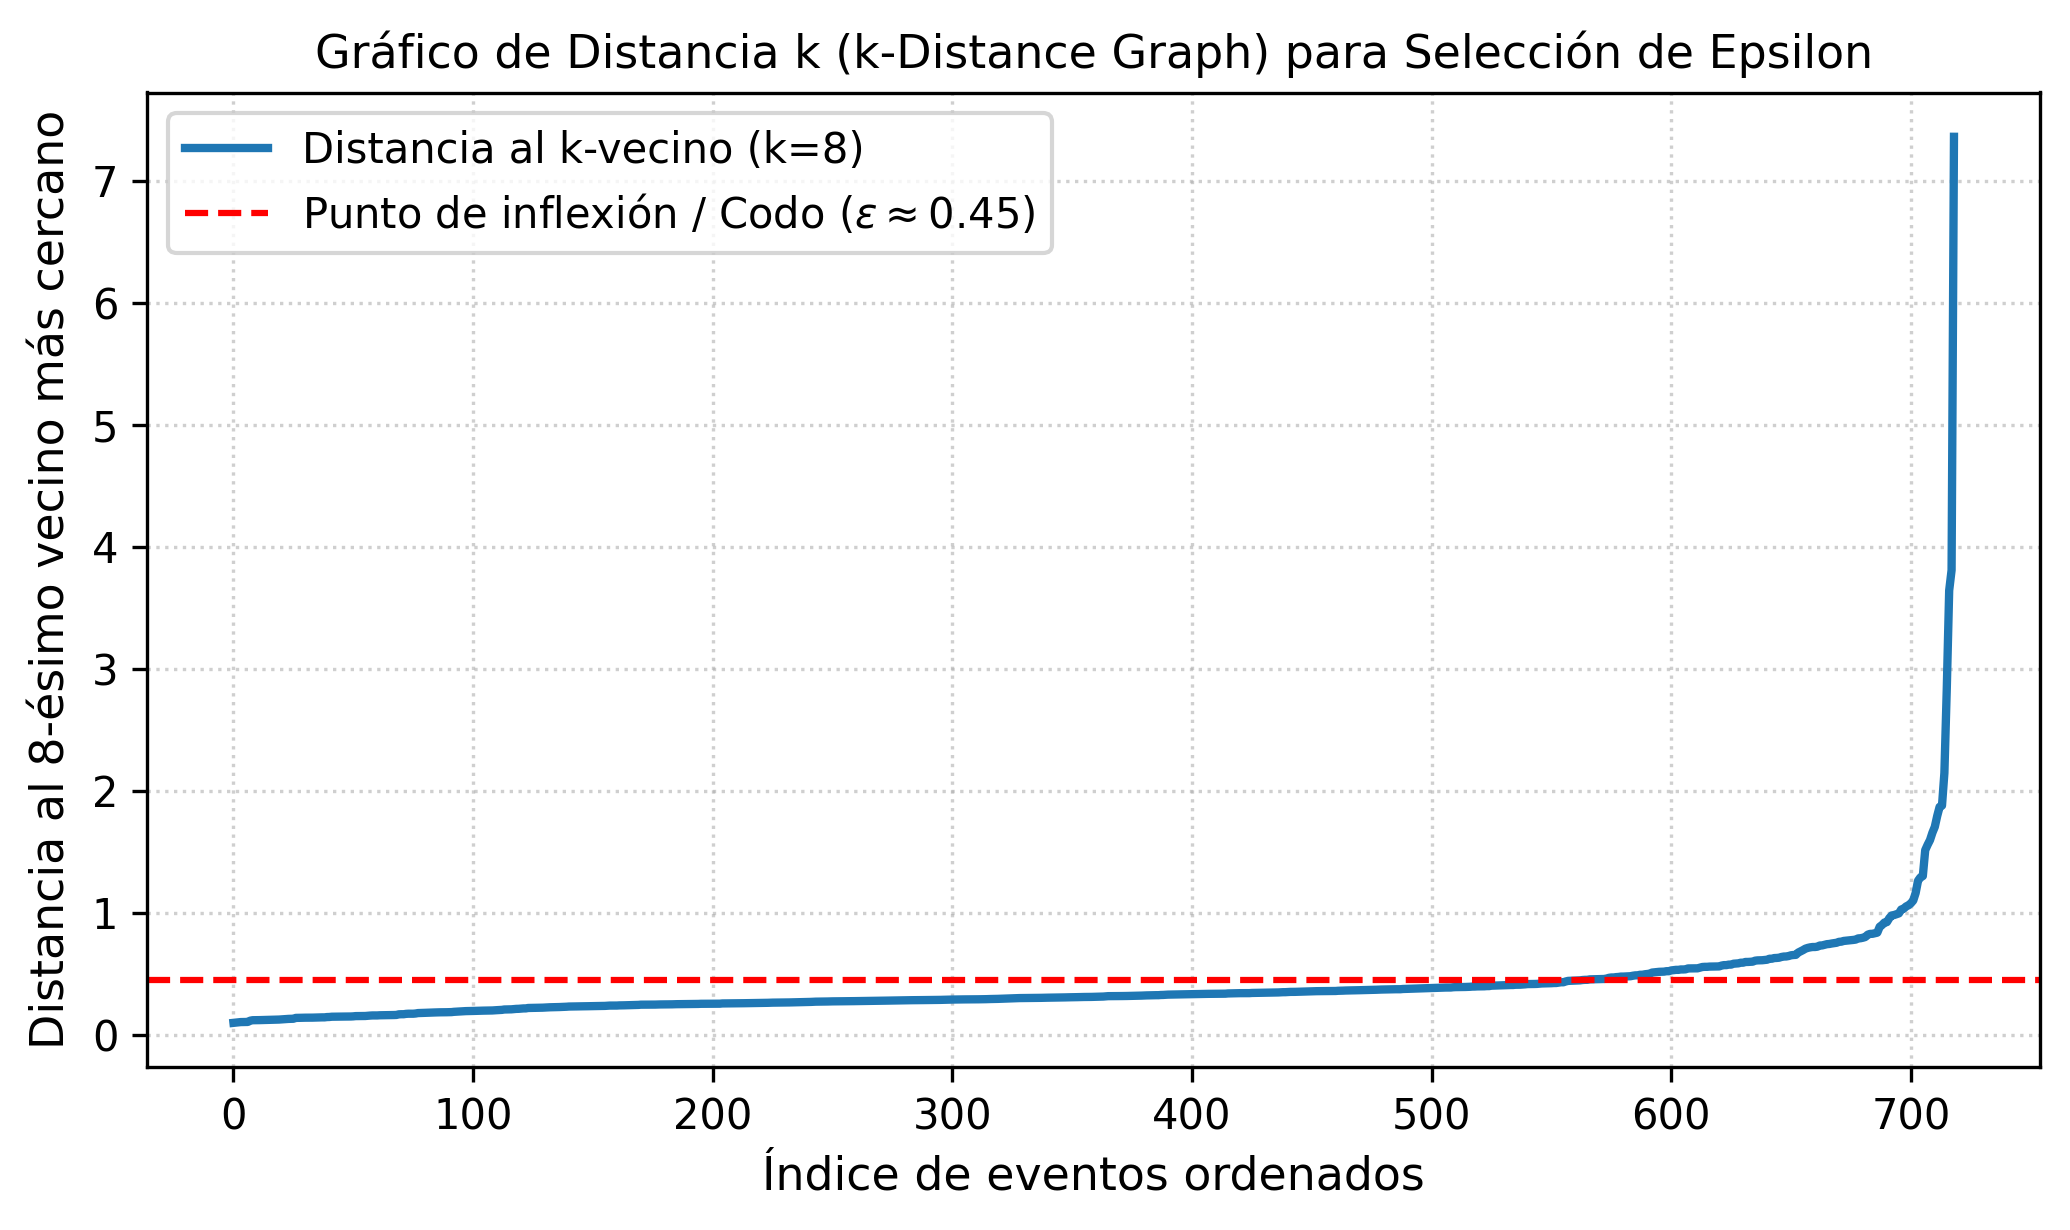

Figura 2 guardada con éxito: 'figura2_k_distance_graph.png' (300 DPI)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
# 1. Normalización de las coordenadas espaciales 3D
# Latitud y longitud están en grados (~111 km/grado) y la profundidad en km.
# StandardScaler nivela las magnitudes para que la distancia euclidiana sea consistente.
X_coords = df[['latitude', 'longitude', 'depth']].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_coords)
# 2. Heurística para MinPts en D dimensiones: MinPts >= 2 * D (3D => k = 8)
k = 8
nn = NearestNeighbors(n_neighbors=k)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
# Tomamos la distancia al k-ésimo vecino más lejano y la ordenamos de menor a mayor
k_distances = np.sort(distances[:, k - 1])
# 3. Generación y guardado de la FIGURA 2 del Paper (300 DPI)
plt.figure(figsize=(7, 4.2), dpi=300)
plt.plot(k_distances, color="#1f77b4", lw=2, label=f"Distancia al k-vecino (k={k})")
plt.axhline(y=0.45, color="red", linestyle="--", label=r"Punto de inflexión / Codo ($\varepsilon \approx 0.45$)")
plt.xlabel("Índice de eventos ordenados", fontsize=11)
plt.ylabel(f"Distancia al {k}-ésimo vecino más cercano", fontsize=11)
plt.title("Gráfico de Distancia k (k-Distance Graph) para Selección de Epsilon", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.savefig("figura2_k_distance_graph.png", dpi=300)
plt.show()
print("Figura 2 guardada con éxito: 'figura2_k_distance_graph.png' (300 DPI)")

---

## Etapa 4: Aplicación del modelo DBSCAN (Agrupamiento espacial en 3D)

### ¿Qué haremos en esta etapa?

- Aplicar el algoritmo **DBSCAN** sobre los datos normalizados en 3D, utilizando los valores de $\varepsilon$ y $MinPts$ que se definieron y justificaron en la etapa anterior.
- Clasificar los sismos en dos grupos principales:
  1. **Clusters densos (grupos de réplicas):** Sismos que se encuentran próximos entre sí y que están relacionados con la zona donde ocurrió la ruptura de la falla geológica.
  2. **Ruido / Outliers (etiqueta -1):** Sismos que se encuentran dispersos y que no forman parte de ningún grupo definido por el modelo. Estos pueden corresponder a sismicidad de fondo o eventos que no están directamente relacionados con la ruptura del terremoto de Illapel.
- Calcular la cantidad de sismos que pertenecen a los grupos identificados y cuántos corresponden a eventos aislados.

In [ ]:
from sklearn.cluster import DBSCAN

# 1. Instanciación y entrenamiento con los parámetros justificados en la Etapa 3
epsilon_optimo = 0.45
minpts_optimo = 8

dbscan = DBSCAN(eps=epsilon_optimo, min_samples=minpts_optimo)
df['cluster'] = dbscan.fit_predict(X_scaled)

# 2. Análisis cuantitativo de los resultados
n_clusters = len(set(df['cluster'])) - (1 if -1 in df['cluster'] else 0)
n_ruido = list(df['cluster']).count(-1)
porcentaje_agrupado = ((len(df) - n_ruido) / len(df)) * 100

print("=== RESULTADOS DEL AGRUPAMIENTO DBSCAN ===")
print(f"Parámetros utilizados: eps = {epsilon_optimo}, min_samples = {minpts_optimo}")
print(f"Clusters densos identificados: {n_clusters}")
print(f"Eventos en la secuencia de réplicas: {len(df) - n_ruido} ({porcentaje_agrupado:.1f}%)")
print(f"Sismicidad dispersa / ruido de fondo (etiqueta -1): {n_ruido} ({100 - porcentaje_agrupado:.1f}%)")
print("-" * 50)
print("Distribución de eventos por grupo:")
print(df['cluster'].value_counts().rename(index={-1: 'Ruido/Aislados'}))

=== RESULTADOS DEL AGRUPAMIENTO DBSCAN ===
Parámetros utilizados: eps = 0.45, min_samples = 8
Clusters densos identificados: 2
Eventos en la secuencia de réplicas: 620 (86.2%)
Sismicidad dispersa / ruido de fondo (etiqueta -1): 99 (13.8%)
--------------------------------------------------
Distribución de eventos por grupo:
cluster
0                 620
Ruido/Aislados     99
Name: count, dtype: int64


---

## Etapa 5: Elaboración de las figuras para el paper (máximo 4)

### Requisitos de la rúbrica y de la plantilla:

- Se permite un máximo de **4 figuras o tablas en total** en todo el artículo.
- Las figuras deben tener una resolución alta, utilizando `dpi=300`.
- Cada figura debe contar con una descripción (*caption*) que explique su contenido por sí sola, sin necesidad de agregar un título adicional que repita la misma información.
- Cada figura debe estar relacionada directamente con alguno de los objetivos de la investigación.

### Las 4 figuras que vamos a utilizar:

1. **Figura 1:** *Mapa 2D de sismicidad epicentral.* Mostrará cómo se distribuyen los sismos en la zona de estudio, destacando el epicentro del sismo principal ($M_w\ 8.3$) y utilizando el tamaño de los puntos para representar la magnitud de cada evento.

2. **Figura 2:** *Gráfico de distancias k (k-distance graph).* Permitirá mostrar cómo se seleccionó el valor del parámetro $\varepsilon$ para DBSCAN, utilizando un criterio objetivo y no una elección al azar. (Esta ya esta hecha en la etapa 3)

3. **Figura 3:** *Representación tridimensional (3D) de los hipocentros.* Permitirá observar la distribución de los sismos en profundidad y visualizar la inclinación de la Placa de Nazca bajo la Placa Sudamericana, mostrando información que no se puede apreciar correctamente en un mapa tradicional en 2D.

4. **Figura 4:** *Clasificación de réplicas mediante DBSCAN.* Mostrará cómo el modelo identifica los grupos de sismos que se encuentran próximos entre sí y los diferencia de aquellos eventos dispersos que son considerados ruido.

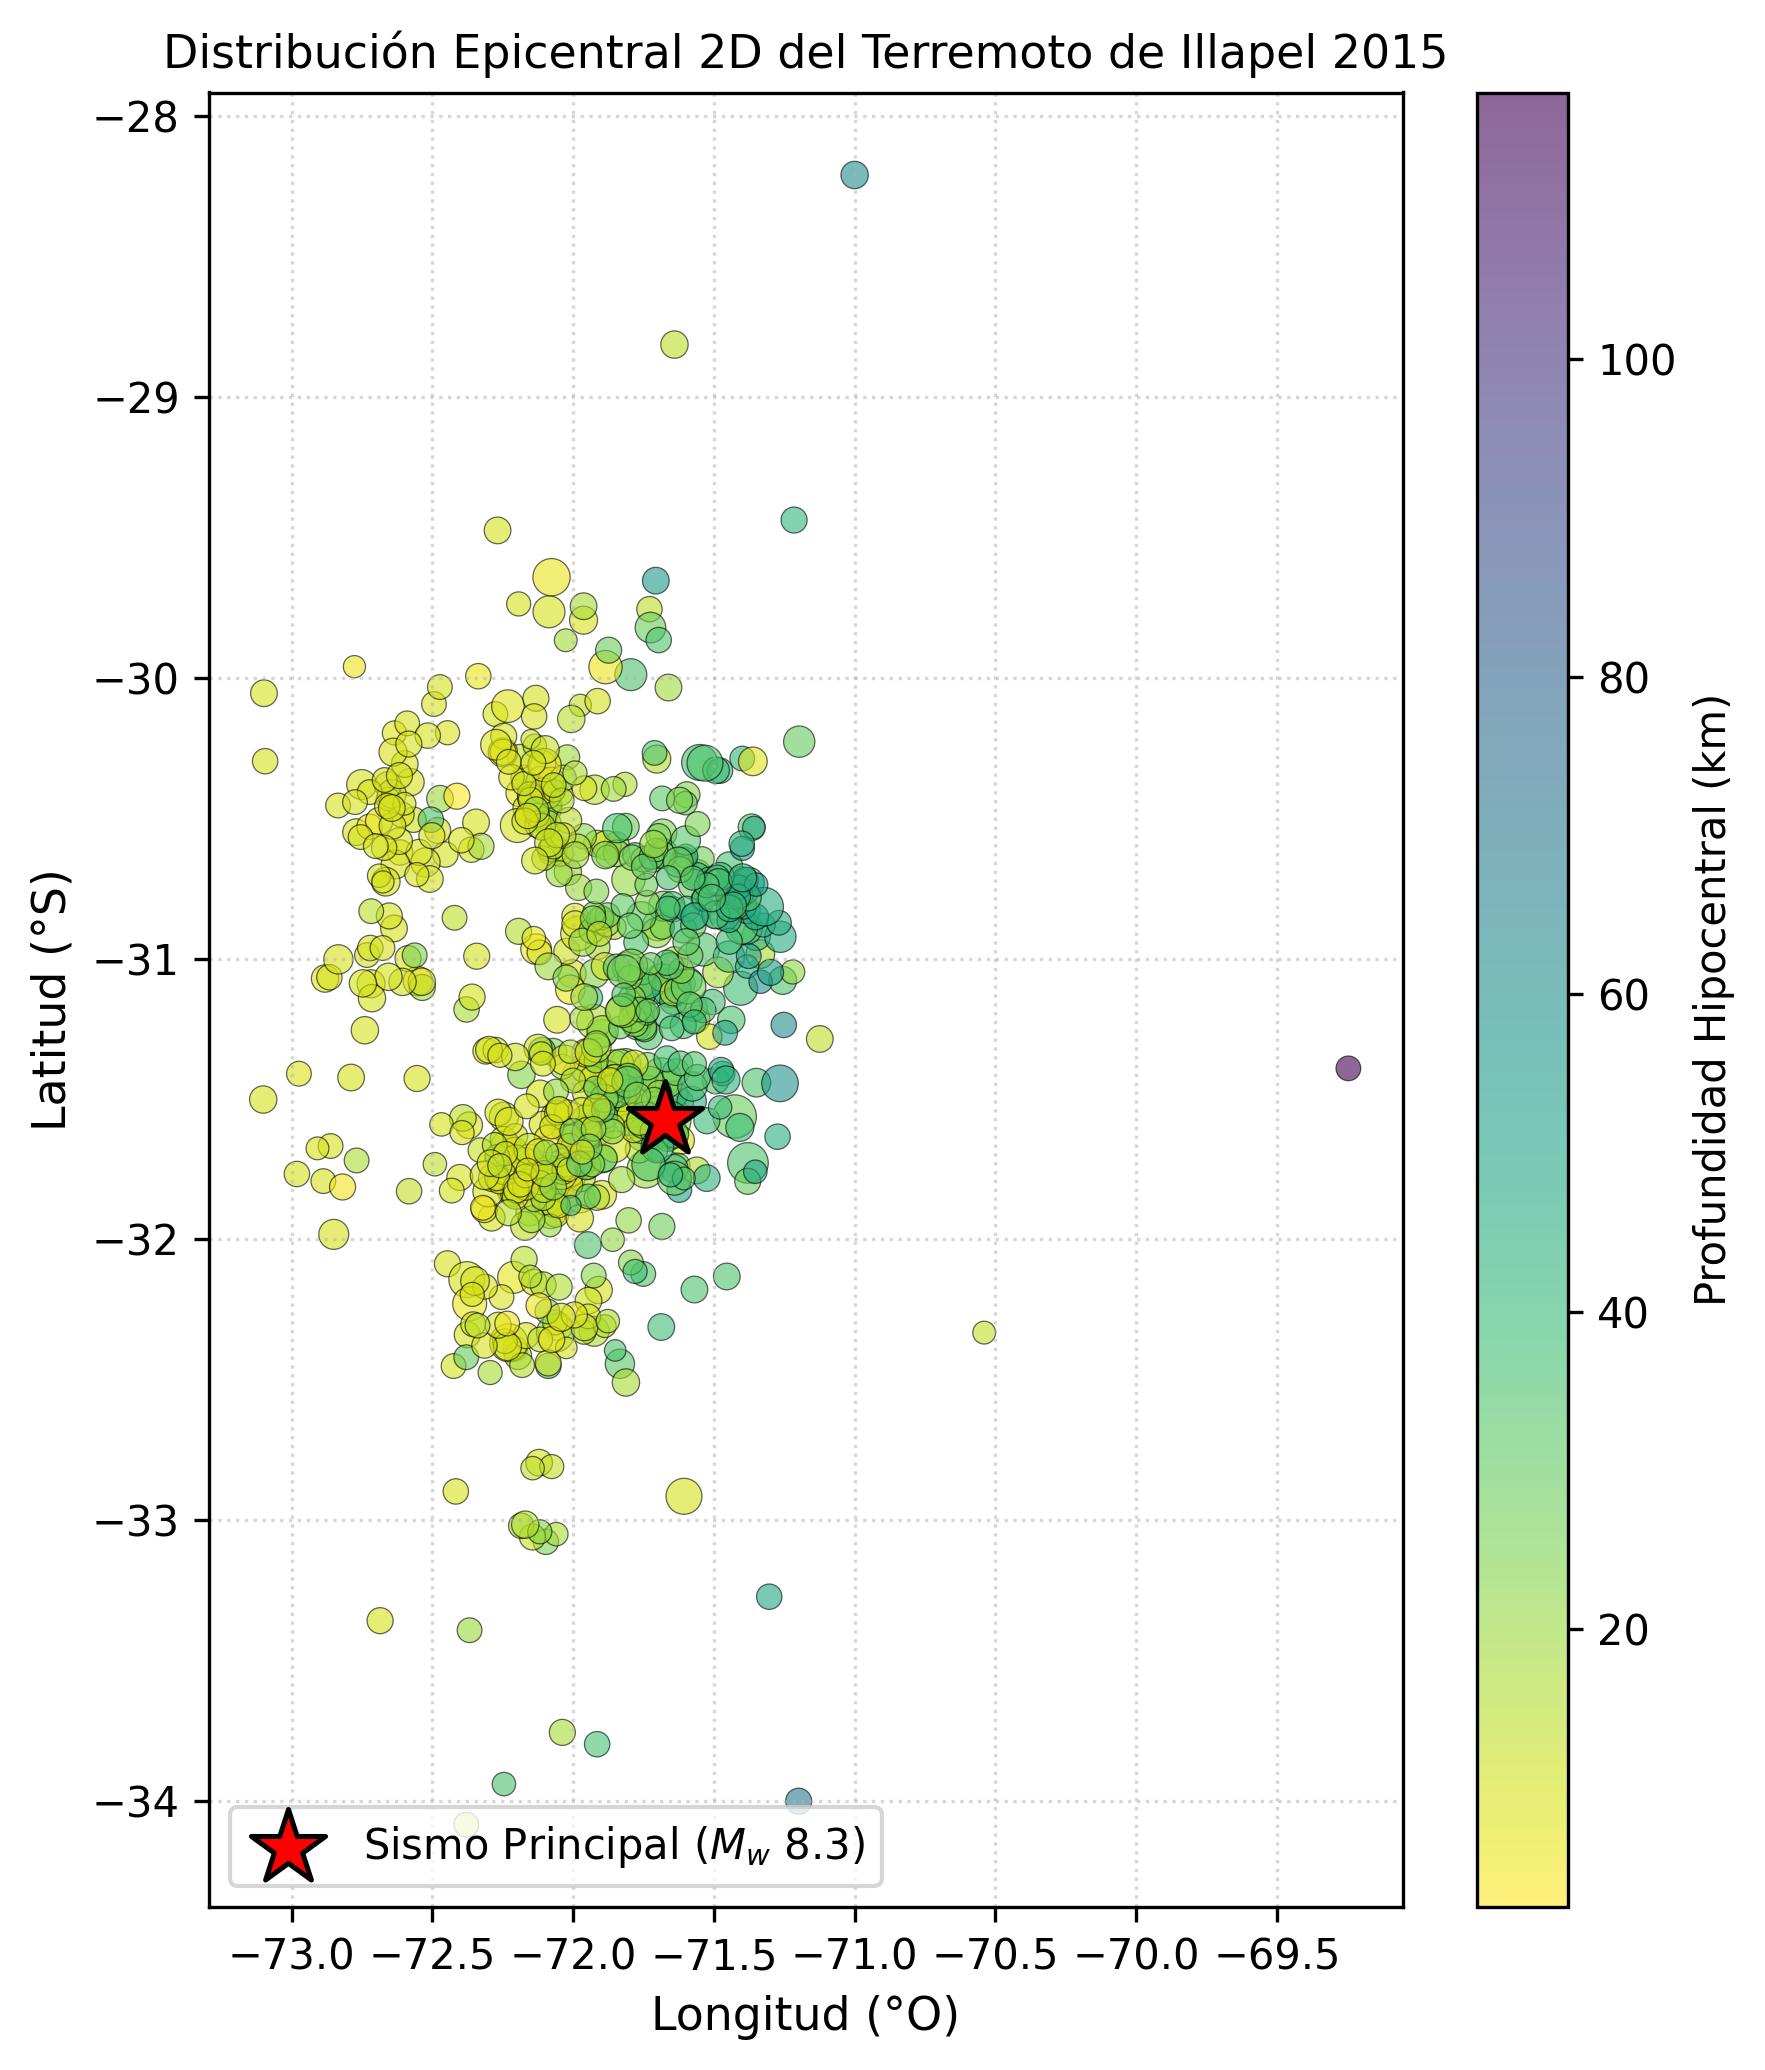

Figura 1 guardada: 'figura1_mapa_epicentros_2d.png'


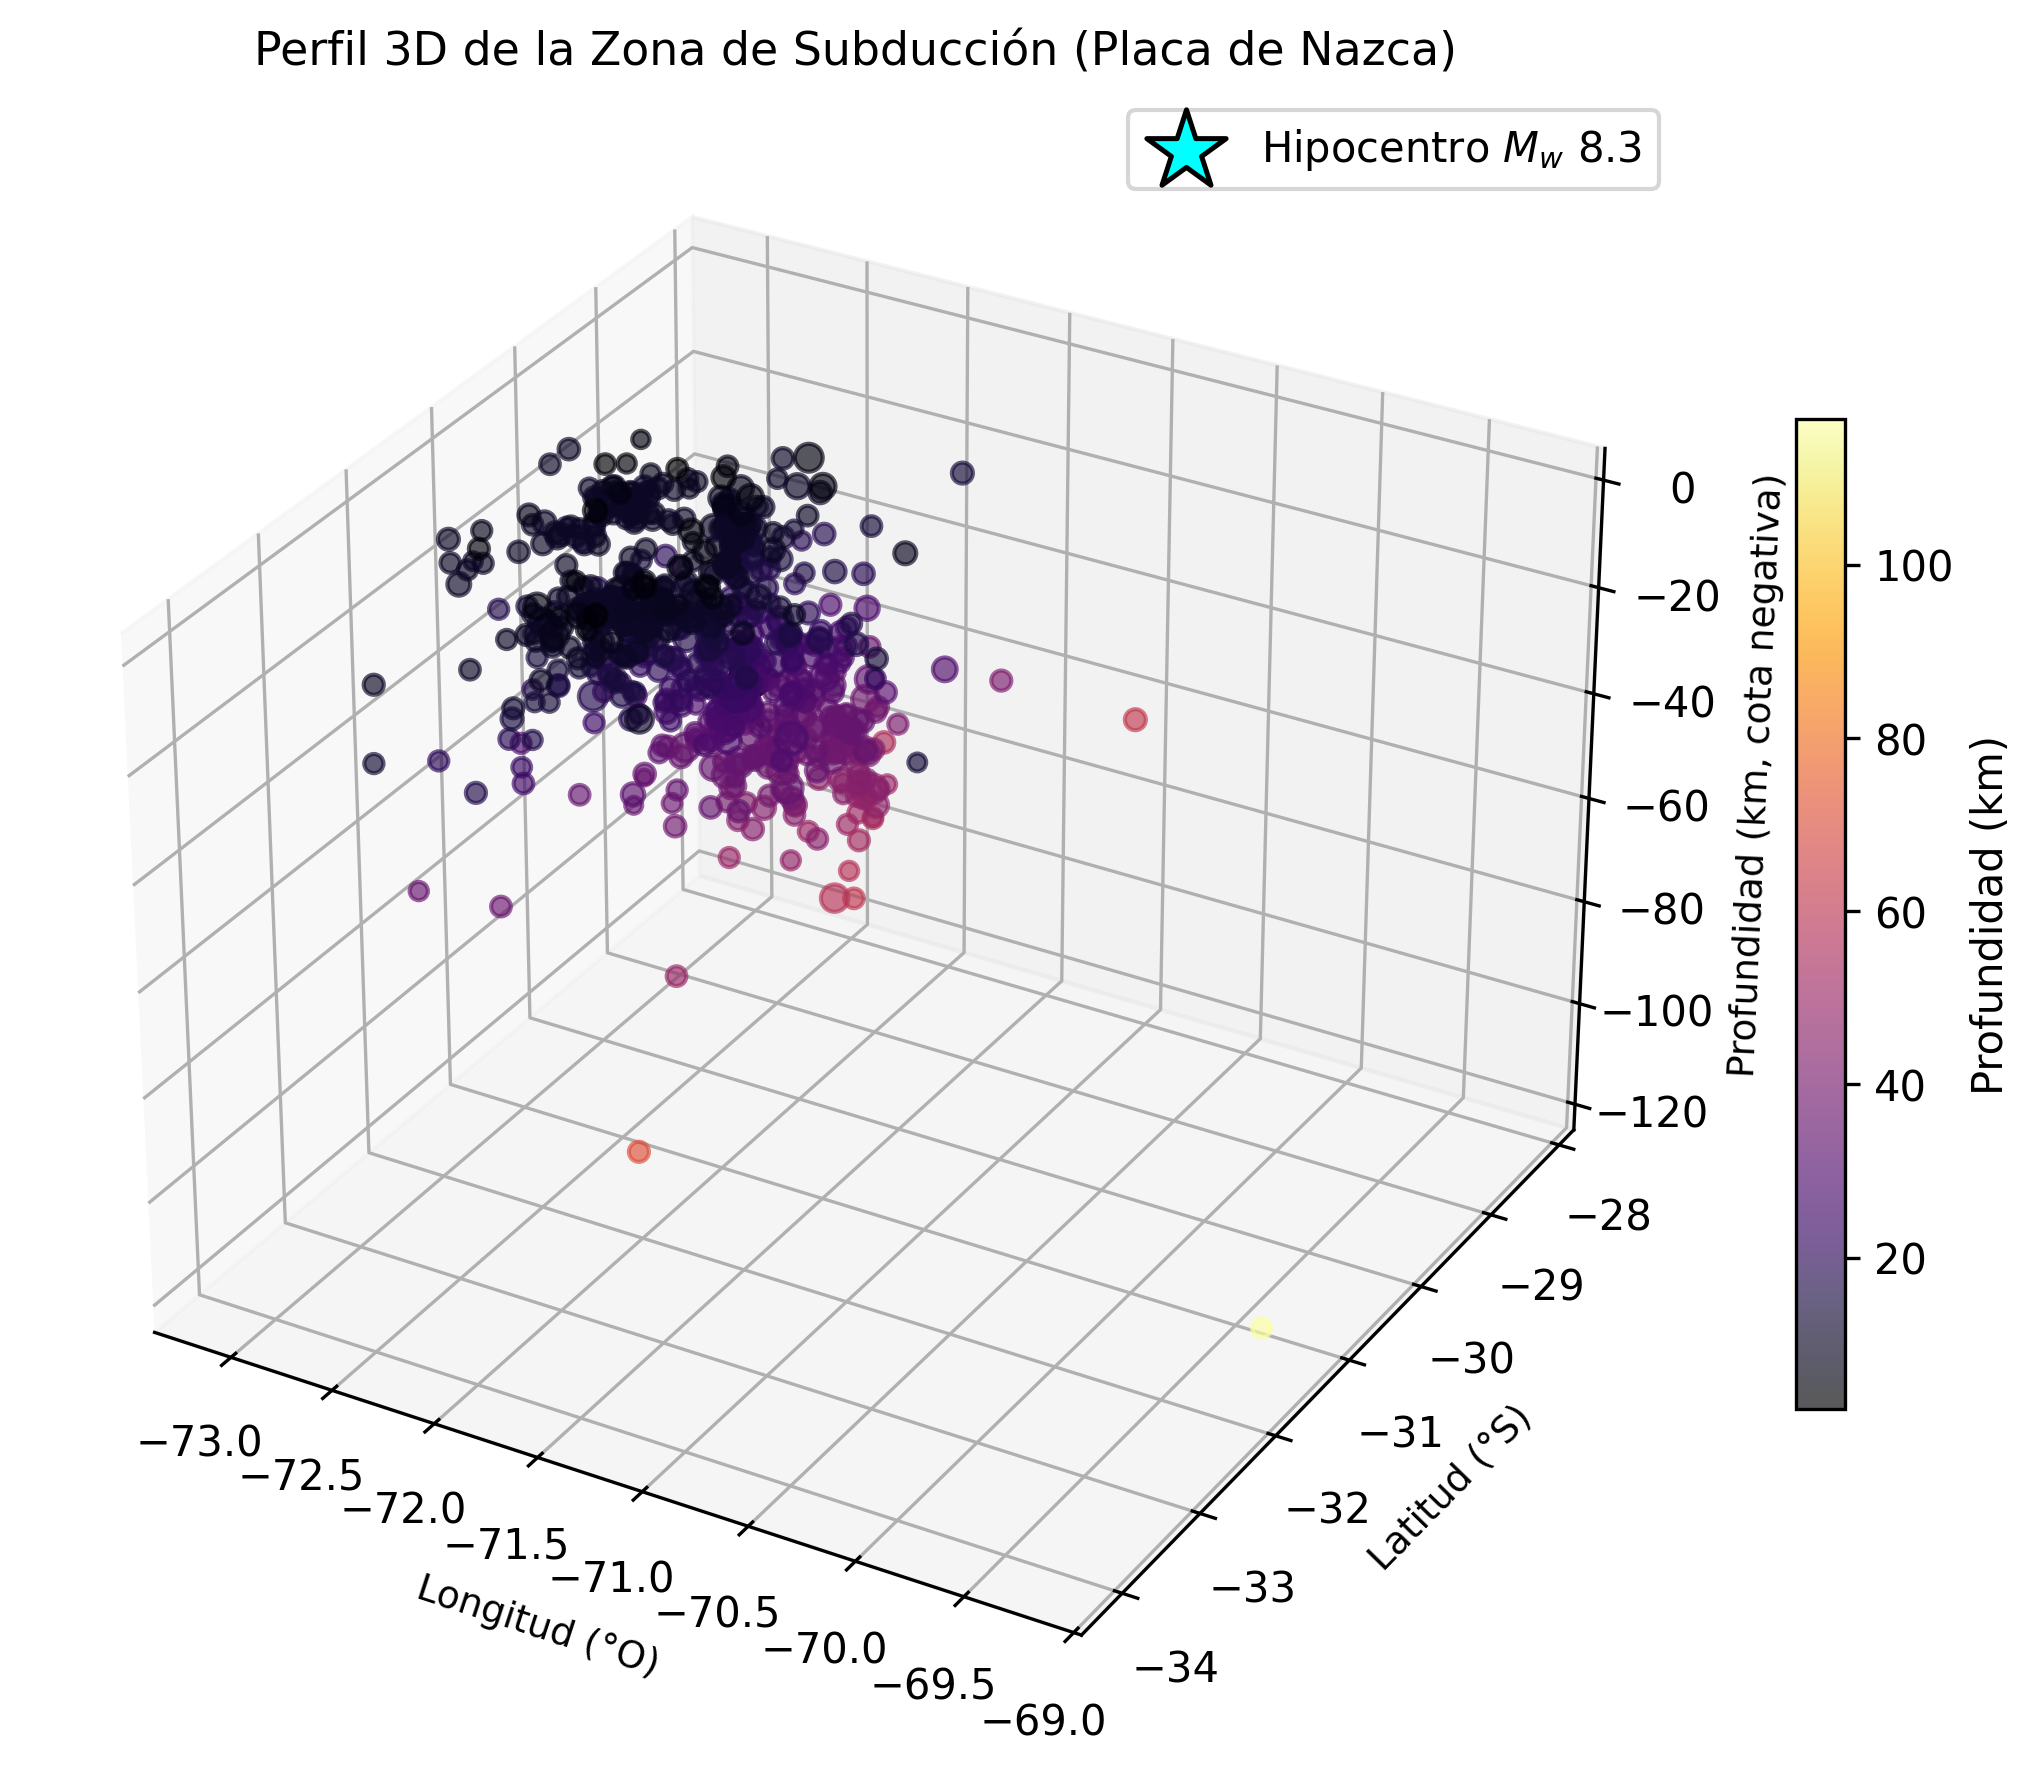

Figura 3 guardada: 'figura3_perfil_subduccion_3d.png'


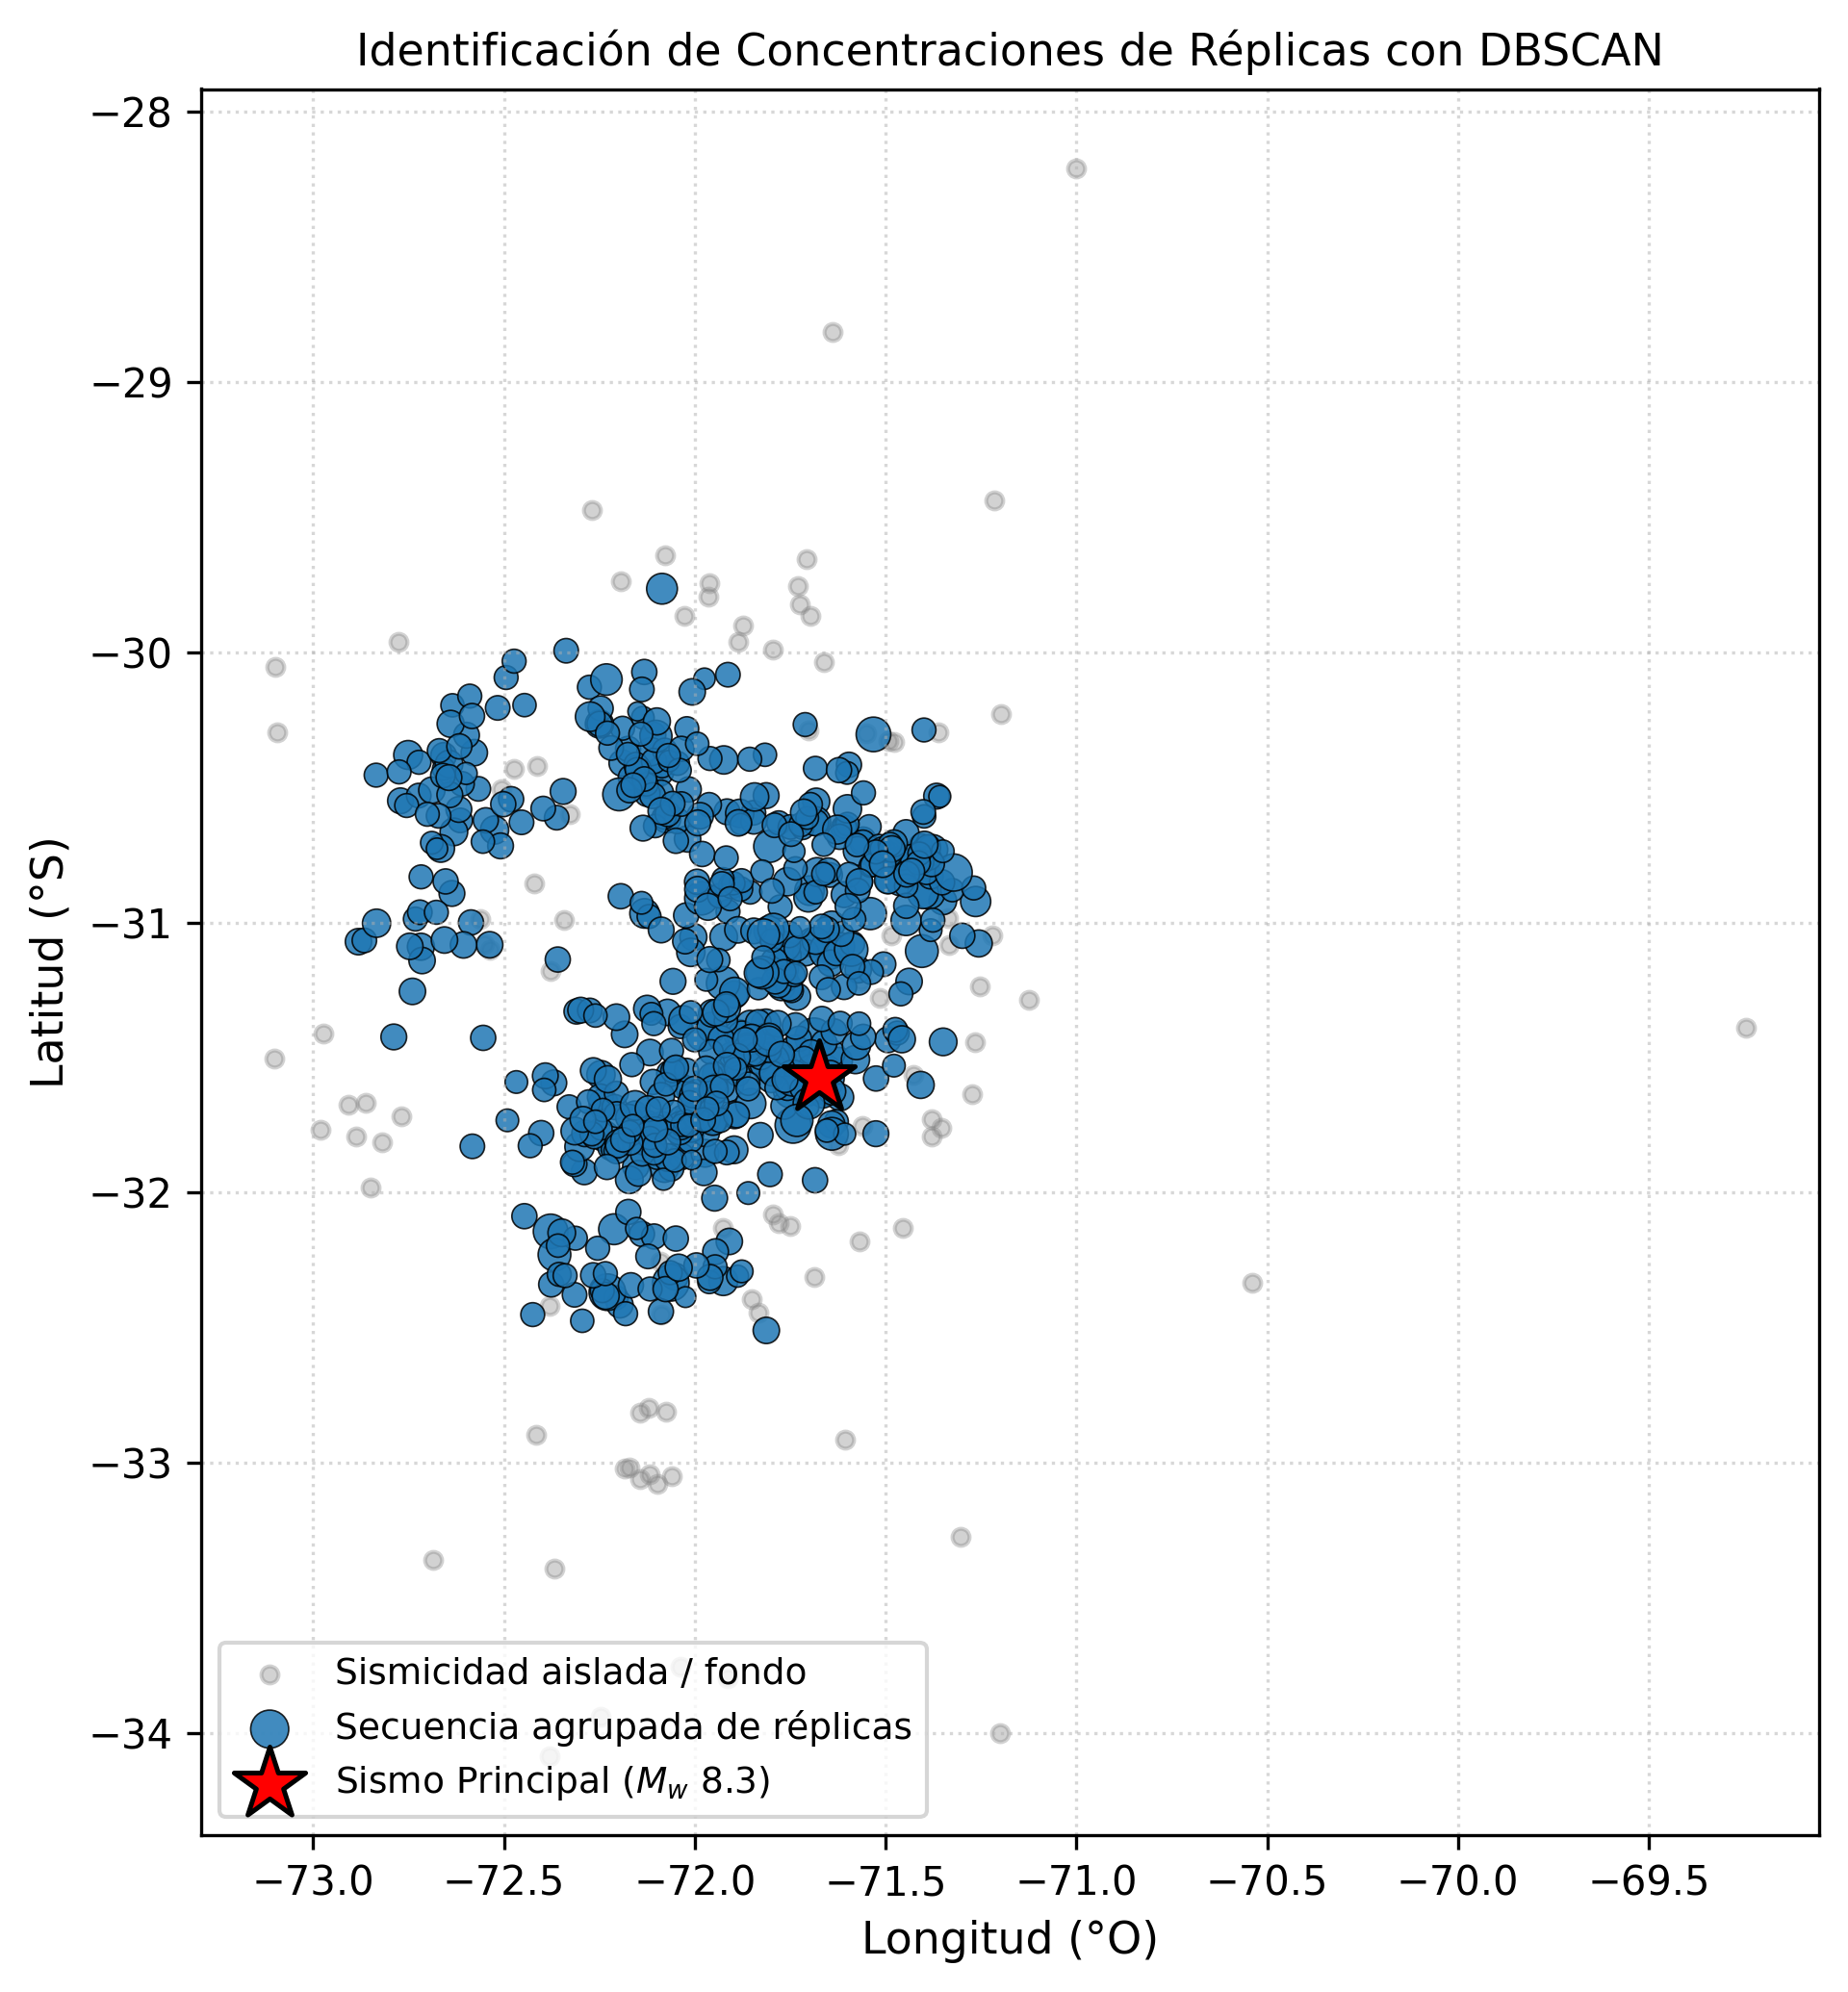

Figura 4 guardada: 'figura4_clusters_dbscan.png'


In [ ]:
# ==============================================================================
# FIGURA 1: Distribución Epicentral 2D de la Secuencia de Illapel 2015
# ==============================================================================
plt.figure(figsize=(6, 7), dpi=300)

sc = plt.scatter(
    df['longitude'], df['latitude'],
    c=df['depth'], cmap='viridis_r',
    s=df['mag']**2.2 * 1.5,
    alpha=0.6, edgecolors='k', linewidth=0.3
)

# Destacar el Sismo Principal (Mw 8.3)
plt.scatter(
    mainshock['longitude'], mainshock['latitude'],
    color='red', marker='*', s=350, edgecolors='black', linewidth=1.2,
    label=f"Sismo Principal ($M_w\\ {mainshock['mag']}$)"
)

cbar = plt.colorbar(sc)
cbar.set_label('Profundidad Hipocentral (km)', fontsize=10)
plt.xlabel('Longitud (°O)', fontsize=11)
plt.ylabel('Latitud (°S)', fontsize=11)
plt.title('Distribución Epicentral 2D del Terremoto de Illapel 2015', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()

plt.savefig('figura1_mapa_epicentros_2d.png', dpi=300)
plt.show()
print("Figura 1 guardada: 'figura1_mapa_epicentros_2d.png'")


# ==============================================================================
# FIGURA 3: Perfil Tridimensional (3D) de la Zona de Subducción (Placa de Nazca)
# ==============================================================================
fig = plt.figure(figsize=(8, 6), dpi=300)
ax = fig.add_subplot(111, projection='3d')

p = ax.scatter(
    df['longitude'], df['latitude'], -df['depth'],
    c=df['depth'], cmap='inferno',
    s=df['mag']**2 * 1.2, alpha=0.65
)

# Hipocentro del evento principal en 3D
ax.scatter(
    [mainshock['longitude']], [mainshock['latitude']], [-mainshock['depth']],
    color='cyan', marker='*', s=400, edgecolors='black', linewidth=1.2,
    label=f"Hipocentro $M_w\\ {mainshock['mag']}$"
)

ax.set_xlabel('Longitud (°O)', fontsize=9)
ax.set_ylabel('Latitud (°S)', fontsize=9)
ax.set_zlabel('Profundidad (km, cota negativa)', fontsize=9)
ax.set_title('Perfil 3D de la Zona de Subducción (Placa de Nazca)', fontsize=11)
fig.colorbar(p, ax=ax, label='Profundidad (km)', shrink=0.6)
ax.legend(loc='upper right')
plt.tight_layout()

plt.savefig('figura3_perfil_subduccion_3d.png', dpi=300)
plt.show()
print("Figura 3 guardada: 'figura3_perfil_subduccion_3d.png'")


# ==============================================================================
# FIGURA 4: Identificación y Segmentación de Réplicas con DBSCAN
# ==============================================================================
plt.figure(figsize=(6.5, 7), dpi=300)

# Sismicidad clasificada como ruido / fondo
df_noise = df[df['cluster'] == -1]
plt.scatter(
    df_noise['longitude'], df_noise['latitude'],
    c='gray', s=18, alpha=0.35, label='Sismicidad aislada / fondo'
)

# Clusters principales de réplicas
df_clusters = df[df['cluster'] != -1]
plt.scatter(
    df_clusters['longitude'], df_clusters['latitude'],
    c=df_clusters['cluster'], cmap='tab10',
    s=df_clusters['mag']**2.2 * 1.5, alpha=0.85,
    edgecolors='black', linewidth=0.4, label='Secuencia agrupada de réplicas'
)

# Sismo principal
plt.scatter(
    mainshock['longitude'], mainshock['latitude'],
    color='red', marker='*', s=350, edgecolors='black', linewidth=1.2,
    label=f"Sismo Principal ($M_w\\ {mainshock['mag']}$)"
)

plt.xlabel('Longitud (°O)', fontsize=11)
plt.ylabel('Latitud (°S)', fontsize=11)
plt.title('Identificación de Concentraciones de Réplicas con DBSCAN', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='lower left', frameon=True, fontsize=9)
plt.tight_layout()

plt.savefig('figura4_clusters_dbscan.png', dpi=300)
plt.show()
print("Figura 4 guardada: 'figura4_clusters_dbscan.png'")

---

## Etapa 6: Obtención de métricas para los resultados y el análisis

### ¿Qué haremos en esta etapa?

- Obtener una tabla resumen con los principales datos numéricos del análisis, que nos servirán para desarrollar los resultados y la discusión del informe. Se considerarán los siguientes datos:
  - Cantidad total de sismos procesados ($M \ge 3.0$).
  - Magnitud máxima registrada ($8.3$) y magnitud promedio de las réplicas.
  - Profundidad promedio y máxima de los sismos registrados, para conocer el rango de profundidad donde se concentra la actividad sísmica.
  - Cantidad y porcentaje de sismos que DBSCAN logró agrupar dentro de la zona de ruptura.
  - Cantidad y porcentaje de sismos que fueron clasificados como sismicidad de fondo o ruido.
- Finalmente, utilizaremos estos valores en la sección *IV. RESULTADOS Y DISCUSIÓN* del informe, para respaldar el análisis con datos concretos y no solamente con interpretaciones visuales.

In [ ]:
import pandas as pd

# 1. Extracción de estadísticas descriptivas del catálogo
total_sismos = len(df)
mag_max = df['mag'].max()
mag_media = df['mag'].mean()
prof_media = df['depth'].mean()
prof_max = df['depth'].max()

# 2. Extracción de estadísticas del agrupamiento DBSCAN
sismos_agrupados = len(df[df['cluster'] != -1])
sismos_ruido = len(df[df['cluster'] == -1])
pct_agrupado = (sismos_agrupados / total_sismos) * 100
pct_ruido = (sismos_ruido / total_sismos) * 100

# 3. Construcción de la tabla consolidada para el informe
tabla_metricas = [
    {"Indicador Metodológico / Sismológico": "Período temporal analizado", "Valor": "15-Sep-2015 a 15-Oct-2015 (30 días)"},
    {"Indicador Metodológico / Sismológico": "Criterio de corte de magnitud", "Valor": "M >= 3.0"},
    {"Indicador Metodológico / Sismológico": "Total de eventos sísmicos registrados", "Valor": f"{total_sismos}"},
    {"Indicador Metodológico / Sismológico": "Magnitud máxima (Sismo Principal)", "Valor": f"Mw {mag_max:.1f}"},
    {"Indicador Metodológico / Sismológico": "Magnitud media de la secuencia", "Valor": f"M {mag_media:.2f}"},
    {"Indicador Metodológico / Sismológico": "Profundidad media hipocentral", "Valor": f"{prof_media:.1f} km"},
    {"Indicador Metodológico / Sismológico": "Rango de profundidad registrado", "Valor": f"{df['depth'].min():.1f} a {prof_max:.1f} km"},
    {"Indicador Metodológico / Sismológico": "Radio de vecindad óptimo (epsilon)", "Valor": "0.45 (espacio normalizado)"},
    {"Indicador Metodológico / Sismológico": "Muestras mínimas por núcleo (MinPts)", "Valor": "8 eventos"},
    {"Indicador Metodológico / Sismológico": "Clusters densos detectados", "Valor": f"{n_clusters}"},
    {"Indicador Metodológico / Sismológico": "Sismos agrupados en la falla activa", "Valor": f"{sismos_agrupados} ({pct_agrupado:.1f}%)"},
    {"Indicador Metodológico / Sismológico": "Sismicidad de fondo / ruido disperso", "Valor": f"{sismos_ruido} ({pct_ruido:.1f}%)"}
]

df_resumen = pd.DataFrame(tabla_metricas)
df_resumen

,Indicador Metodológico / Sismológico,Valor
0,Período temporal analizado,15-Sep-2015 a 15-Oct-2015 (30 días)
1,Criterio de corte de magnitud,M >= 3.0
2,Total de eventos sísmicos registrados,719
3,Magnitud máxima (Sismo Principal),Mw 8.3
4,Magnitud media de la secuencia,M 4.50
5,Profundidad media hipocentral,21.0 km
6,Rango de profundidad registrado,2.5 a 116.8 km
7,Radio de vecindad óptimo (epsilon),0.45 (espacio normalizado)
8,Muestras mínimas por núcleo (MinPts),8 eventos
9,Clusters densos detectados,2


## Etapa 7: Documentación y estructura del Dashboard interactivo (`app.py`)

### Propósito del módulo de producción

Una vez que el análisis realizado en este cuaderno esté completo y validado, pasaremos los modelos de agrupamiento y las técnicas de visualización a una aplicación web independiente, que estará dentro del archivo `app.py` del repositorio.

La idea es que cualquier persona, incluso si no tiene conocimientos de programación, pueda utilizar la aplicación para explorar los datos y visualizar los resultados de forma interactiva.

### Estructura y componentes de `app.py`:

1. **Módulo de adquisición y almacenamiento en caché:**
   - Utilizaremos `@st.cache_data` para guardar temporalmente los datos procesados y los resultados del modelo DBSCAN, evitando tener que ejecutar nuevamente todo el procesamiento cada vez que se utilice la aplicación.
   - Si el archivo `illapel_2015_usgs.csv` no se encuentra disponible localmente, la aplicación lo descargará automáticamente desde la API del USGS.

2. **Panel de control lateral (filtros dinámicos):**
   - **Selector de rango de magnitud:** Permitirá filtrar los sismos según su magnitud, pudiendo seleccionar eventos de mayor intensidad ($\ge 6.0$) o visualizar todas las réplicas.
   - **Selector de periodo de tiempo:** Permitirá seleccionar fechas mediante un calendario para observar cómo ha evolucionado la actividad sísmica.
   - **Filtro de agrupamientos sismológicos:** Permitirá diferenciar los grupos de réplicas relacionados con la falla activa de los sismos que fueron clasificados como ruido o eventos aislados.

3. **Panel de métricas principales (KPIs):**
   - Incorporaremos cuatro tarjetas en la parte superior que se actualizarán según los filtros seleccionados. Estas mostrarán la cantidad de eventos visibles, la magnitud máxima, la profundidad promedio y el porcentaje de sismos pertenecientes a la falla activa.

4. **Pestañas de visualización:**
   - **Pestaña 1 (Mapa geoespacial 2D):** Incorporaremos un mapa interactivo utilizando OpenStreetMap mediante `scatter_map`. Esto permitirá responder a la observación realizada por el profesor en la primera entrega, pudiendo acercar el mapa para observar las localidades afectadas, como Illapel, Salamanca, Los Vilos y Coquimbo.
   - **Pestaña 2 (Perfil 3D de subducción):** Contará con un visor tridimensional mediante `scatter_3d`, que permitirá rotar la visualización en 360° y utilizar el zoom para observar cómo los hipocentros alcanzan mayores profundidades hacia el continente.
   - **Pestaña 3 (Evolución temporal):** Mostrará un gráfico de dispersión temporal para analizar cómo disminuye la actividad sísmica con el paso del tiempo, permitiendo observar el comportamiento de las réplicas según la ley de decaimiento de Omori.